<a href="https://colab.research.google.com/github/pazolka/ai-climate-workshop-dhaka/blob/main/template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2. Gap Filling

Environmental data have gaps - this is unevitable! Especially time-series with strong seasonality and trends need careful treatment. Again, let's have a look at BWDB groundwater level dataset to learn about possible approaches.

Size of the dataset: (468, 13)


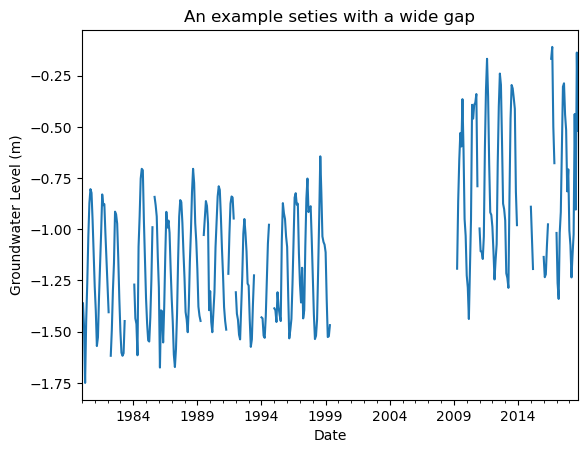

In [18]:
import warnings
warnings.filterwarnings('ignore', message='.*Google will stop supporting.*')

import pandas as pd
import matplotlib.pyplot as plt

# reading the BWDB groundwater level data from a csv file
gwl_data = pd.read_csv('../data/point_observations/BWDB_gwl_ts_monthly.csv', parse_dates=True, index_col='Date')

# setting the index to monthly period explicitly
gwl_data.index = gwl_data.index.to_period('M')
gwl_data = gwl_data.reindex(pd.period_range(gwl_data.index.min(), gwl_data.index.max(), freq='M'))

# clipping every series to its own observation span: dropping leading/trailing NaNs,
gwl_series = {
    col: s.loc[s.first_valid_index():s.last_valid_index()]
    for col, s in gwl_data.items()
}

print("Size of the dataset:", gwl_data.shape)

# an example time series data with a wide gap
id = 'BA016' # DH088 BA016
gwl_series[id].plot()
plt.gca().set(title='An example seties with a wide gap', xlabel='Date', ylabel='Groundwater Level (m)');

### 2.1. Kalman Filter

Groundwater time series show a strong seasonality that can change over time. Reconstructing variable seasonal signal can be achieved with Kalman filter. It keeps a running estimate of the groundwater level and its yearly cycle, updating that estimate whenever a new measurement arrives; when a month is missing, it carries its best estimate forward. Later measurements are then used to revise that estimate, drawing on what came both before and after the gap (smoothing). The filled values follow the overall trend and seasonal pattern.

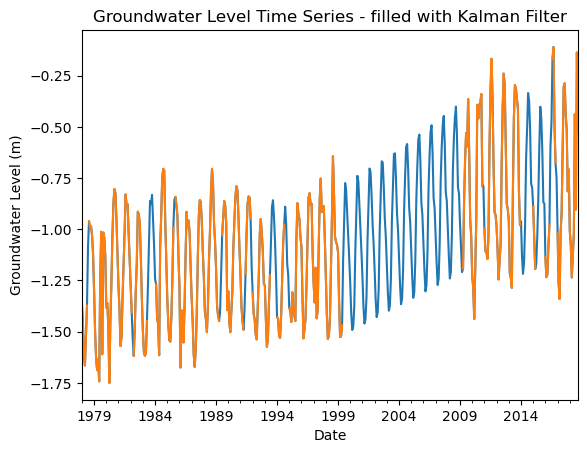

In [2]:
# necessary imports
import numpy as np
from statsmodels.tsa.statespace.structural import UnobservedComponents

well = gwl_series[id].copy()                      
well.index = well.index.to_timestamp()

# Step 1: Defining the model
model = UnobservedComponents(
    well,
    level=True,                  # stochastic level (random walk)
    seasonal=12,                 # annual cycle for monthly data
    stochastic_level=True,
    stochastic_seasonal=True,    # let the seasonal pattern evolve
    irregular=True,
    use_exact_diffuse=True,
)

# Step 2: Fitting the model
res = model.fit(disp=False, maxiter=1000)

# Step 3: Extracting the smoothed forecasts
smoothed = np.asarray(res.smoother_results.smoothed_forecasts).ravel()

well_filled = well.copy()
well_filled[well.isna()] = smoothed[well.isna().values]

# Visualisation
well_filled.plot()
well.plot()
plt.gca().set(title='Groundwater Level Time Series - filled with Kalman Filter', xlabel='Date', ylabel='Groundwater Level (m)');


This looks interesting! As the gap is very large, we can suspect that the two segments may be associated with different wells that carry the same id. This is up to the expert to decide whether this series should be split, or gap filled with substantial uncertainty.

### 2.2.  Random forest (RF)

So far we've seen how to fill gaps using the observations of an individual time series (univariate).

Random forest is a versatile machine learning model that can also be used for gap filling. It _learns from the other wells_: where a well was measured, it learns how that well's level relates to the others, and then uses those relationships to estimate the missing months. Because it borrows information from many wells at once, it can fill gaps that a single well's own history cannot - but it needs a reasonably dense network of wells to work well.

In [3]:
import numpy as np
from sklearn.experimental import enable_iterative_imputer  # Required to unlock IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

# Step 1: Set up the IterativeImputer using RandomForestRegressor as the estimator
rf_imputer = IterativeImputer(
    estimator=RandomForestRegressor(
        n_estimators=100,
        max_features='sqrt',
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42,
    ),
    max_iter=10,
    random_state=42
)

# Step 2: Fit and transform the data
imputed_array = rf_imputer.fit_transform(gwl_data)

# Step 3: Convert it back to a Pandas DataFrame and clip each series to its observation span
gwl_data_filled = pd.DataFrame(imputed_array, columns=gwl_data.columns, index=gwl_data.index)

for col in gwl_data.columns:
    first = gwl_data[col].first_valid_index()
    last = gwl_data[col].last_valid_index()
    gwl_data_filled.loc[(gwl_data_filled.index < first) | (gwl_data_filled.index > last), col] = np.nan

/home/anna/anaconda3/envs/phd/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


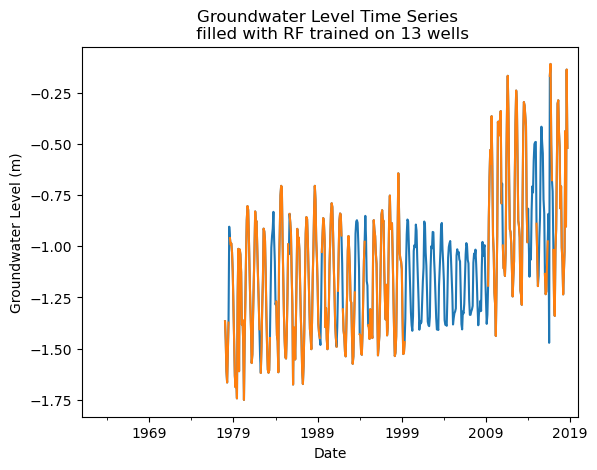

In [4]:
gwl_data_filled[id].plot()
gwl_data[id].plot()

plt.gca().set(title='Groundwater Level Time Series \n filled with RF trained on 13 wells', xlabel='Date', ylabel='Groundwater Level (m)')
print()

As we can see, the reconstruction pattern is quite poor. The RF model was trained on a tiny subset of the BWDB dataset (13 wells), which is not sufficient for learning a generalisable relationship from the data. Below, we can see how the prediction changes when the model was trained with 300 wells - notice that it also affects the smaller post-2015 gap! 

![RF imputation with 300 wells](rf_imputation_300_wells.png)

### 2.3. RF with precipitation as an additional covariate

Groundwater levels respond to rainfall with a lag. The previous section used only the other wells to fill gaps in our BWDB dataset. Here we add one rainfall covariate per well: ERA5 monthly precipitation sampled at the well location and shifted by one month (the previous month). The rainfall columns are complete, so the imputer can use them as predictors while it estimates the missing groundwater values.

In [19]:
import xarray as xr

# Step 1: Read the data

# station coordinates for the 13 wells
wells = pd.read_csv('../data/point_observations/BWDB_gwl_station_info.csv')

# sample ERA5 precipitation at every well (nearest cell)
era5 = xr.open_dataset('../data/gridded/ERA5_precip_M_acc_1972_2020_BGD_025.nc')
well_lat = xr.DataArray(wells['Latitude'].values, dims='well')
well_lon = xr.DataArray(wells['Longitude'].values, dims='well')

rain = (era5['pr']
        .sel(lat=well_lat, lon=well_lon, method='nearest')
        .assign_coords(well=wells['WellID'].values)
        .rename(time='Date')
        .to_dataframe(name='rain')['rain']
        .unstack('well'))
rain.index = pd.to_datetime(rain.index).to_period('M')
rain = rain[wells['WellID'].tolist()]

# shift rainfall by one month (previous month) and restrict to the ERA5 period
period = slice('1972-02', '2019-12')
gwl = gwl_data.loc[period]
rain_lag1 = rain.shift(1).loc[period].add_suffix('_rain_lag1')

print('GWL:', gwl.shape, '| rainfall covariates:', rain_lag1.shape)
rain_lag1[['BA016_rain_lag1', 'MY050_rain_lag1']].head()

GWL: (468, 13) | rainfall covariates: (575, 13)


well,BA016_rain_lag1,MY050_rain_lag1
Date,,
1972-02,0.118256,11.766434
1972-03,57.359695,19.276619
1972-04,22.764206,24.863243
1972-05,75.473785,114.097595
1972-06,186.193466,143.325806


In [21]:
# Step 2: set up the same imputer as above, now with the rainfall columns added
X = pd.concat([gwl, rain_lag1], axis=1)

rf_imputer = IterativeImputer(
    estimator=RandomForestRegressor(
        n_estimators=100,
        max_features='sqrt',
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42,
    ),
    max_iter=10,
    random_state=42
)

# Step 3: Train the model and impute the missing values
imputed = pd.DataFrame(rf_imputer.fit_transform(X), columns=X.columns, index=X.index)
gwl_filled_rain = imputed[gwl.columns].copy()

# keep leading/trailing NaNs outside each well's observation span
for col in gwl.columns:
    first, last = gwl[col].first_valid_index(), gwl[col].last_valid_index()
    gwl_filled_rain.loc[(gwl_filled_rain.index < first) | (gwl_filled_rain.index > last), col] = np.nan

/home/anna/anaconda3/envs/phd/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


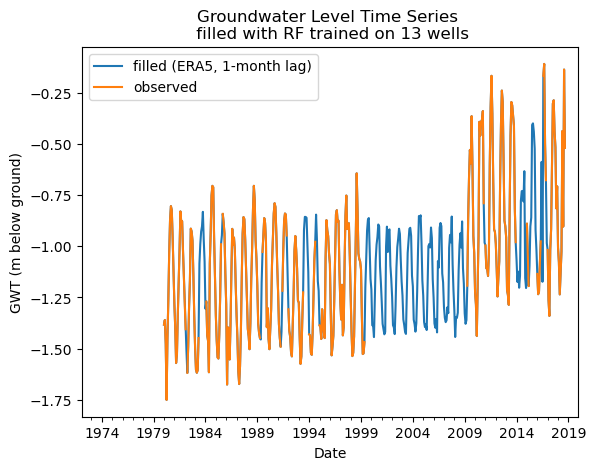

In [22]:
# Visualise
#gwl_data_filled[id].plot(label='filled (wells only)')
gwl_filled_rain[id].plot(label='filled (ERA5, 1-month lag)')
gwl_data[id].plot(label='observed')

ax = plt.gca()
ax.set(title='Groundwater Level Time Series \n filled with RF trained on 13 wells', xlabel='Date', ylabel='Groundwater Level (m)')
ax.set_ylabel('GWT (m below ground)')
ax.legend()

### Summary

Some machine learning models cannot handle missing data, but environmental data often have gaps. As we have seen, gaps can be filled using a series' own history (a univariate approach) or the values of neighbouring series (a multivariate approach). Expert knowledge is still needed to judge when a gap is too long to fill reliably, because the uncertainty of the estimate grows substantially with the length of the gap.

### Bonus: deep learning - based methods

The research on foundational time series models is progressing, and there are hundreds of deep learning models that can be applied for data imputation. This is a helpful page that lists the state-of-the-art approaches and is a great start for more advanced experiments! https://github.com/WenjieDu/PyPOTS/tree/main 

Note that many of DL models require large datasets.